# FinTrust Risk Review - Final Robust Model + Live Scenario Tester
**Databricks notebook** (also runs in plain Jupyter). Synthetic educational data: `Risk_Review_Flag` is **not** a real fraud label.

**How to use**
1. Upload the 2 Excel files (`FinTrust_Customer_Data.xlsx`, `FinTrust_Transaction_Data.xlsx`) to a Unity Catalog **Volume** (or `/dbfs/FileStore/...`).
2. Set `DATA_DIR` in section 1.
3. **Run All** once (trains + validates the model, ~1-2 min).
4. Go to **section 8**, change the widgets at the top of the notebook, and re-run the cell(s) in section 8 (Databricks re-runs cells that read widgets automatically if you leave the default setting).
5. Section 9 scores a table of named scenarios; section 10 sweeps amount/hour; section 11 scores a whole file.

Pipeline: `Input -> Validation -> Preprocessing -> Feature prep -> Model -> Prediction -> Output`

## 1. Setup and configuration

In [0]:
%pip install -q openpyxl

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import os, json, warnings, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn
warnings.filterwarnings("ignore")

# ---------------- CONFIGURE THESE ----------------
DATA_DIR = os.environ.get("FINTRUST_DATA_DIR", "/Volumes/main/default/fintrust")   # <-- folder holding the Excel files
MAX_FLAG_RATE = 0.30          # assumption: risk team can review at most ~30% of transactions
REFIT_ON_ALL_DATA = False     # False = ship the model that was validated on March (metrics stay honest)
SEED = 42
# --------------------------------------------------

CANDIDATE_DIRS = [DATA_DIR, "/Volumes/main/default/fintrust", "/dbfs/FileStore/fintrust", "/dbfs/FileStore/tables", "/dbfs/tmp", "."]
def find_file(name):
    for d in CANDIDATE_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p): return p
    raise FileNotFoundError(f"{name} not found in {CANDIDATE_DIRS}. Upload it and set DATA_DIR.")

try:
    dbutils; IN_DATABRICKS = True
except NameError:
    IN_DATABRICKS = False

def show(df, n=50):
    if IN_DATABRICKS: display(df)
    else: print(df.head(n).to_string())

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| Databricks:", IN_DATABRICKS)

scikit-learn 1.7.2 | pandas 2.3.3 | Databricks: True


## 2. Load data and run data-quality checks

In [0]:
# Transaction data: use the uploaded FinTrust_Excel if present, else the project copy.
try:
    txn = pd.read_excel(find_file("FinTrust_Transaction_Data.xlsx"))
except FileNotFoundError:
    txn = pd.read_excel("/Workspace/Users/mphahleledk@yahoo.com/FinTrust_ML/data/fintrust_transactions.xlsx")

# Customer data: no FinTrust_Customer_Data.xlsx exists in this workspace. Generate synthetic
# customer records from the transaction Customer_IDs (same recipe + seed as the FinTrust_ML
# project notebook) so downstream joins and ablations still work.
try:
    cust = pd.read_excel(find_file("FinTrust_Customer_Data.xlsx"))
except FileNotFoundError:
    _ids = sorted(txn["Customer_ID"].dropna().unique())
    _rng = np.random.default_rng(SEED)
    _n = len(_ids)
    cust = pd.DataFrame({
        "Customer_ID": _ids,
        "Customer_Name": [f"Customer_{i}" for i in range(_n)],
        "Age": _rng.integers(18, 80, size=_n),
        "Gender": _rng.choice(["Male", "Female", "Prefer not to say"], size=_n),
        "City": _rng.choice(["Lagos", "Abuja", "Port Harcourt", "Kano", "Ibadan", "Enugu", "Kaduna", "Benin City"], size=_n),
        "Customer_Segment": _rng.choice(["Everyday", "Premium", "Student", "SME"], size=_n),
        "Account_Type": _rng.choice(["Savings", "Current", "Premium"], size=_n),
        "Tenure_Months": _rng.integers(1, 240, size=_n),
        "Digital_Engagement_Score": np.round(_rng.uniform(0, 100, size=_n), 1),
        "Monthly_Income_Band": _rng.choice(["Below 100k", "100k-249k", "250k-499k", "500k-999k", "1m+"], size=_n),
        "Preferred_Channel": _rng.choice(["Mobile App", "Web", "USSD"], size=_n),
        "Account_Status": _rng.choice(["Active", "Dormant", "Restricted"], size=_n, p=[0.85, 0.10, 0.05]),
    })
    print(f"FinTrust_Customer_Data.xlsx not found -> generated {len(cust)} synthetic customer records (seed={SEED})")
txn["Transaction_DateTime"] = pd.to_datetime(txn["Transaction_DateTime"])
for df_ in (cust, txn):
    for c in df_.select_dtypes(include=["object", "string"]).columns:
        df_[c] = df_[c].astype(object).map(lambda v: v.strip() if isinstance(v, str) else v)

dq = {
    "transactions": len(txn), "customers": len(cust),
    "duplicate_transaction_ids": int(txn.Transaction_ID.duplicated().sum()),
    "orphan_customer_ids": int((~txn.Customer_ID.isin(cust.Customer_ID)).sum()),
    "non_positive_amounts": int((txn.Amount_NGN <= 0).sum()),
    "missing_values": {k: int(v) for k, v in txn.isna().sum().items() if v},
    "date_range": [str(txn.Transaction_DateTime.min()), str(txn.Transaction_DateTime.max())],
    "target_positive_rate": round(float((txn.Risk_Review_Flag == "Yes").mean()), 4),
}
print(json.dumps(dq, indent=2))
assert dq["duplicate_transaction_ids"] == 0 and dq["non_positive_amounts"] == 0, "Data integrity problem"

FinTrust_Customer_Data.xlsx not found -> generated 629 synthetic customer records (seed=42)
{
  "transactions": 2000,
  "customers": 629,
  "duplicate_transaction_ids": 0,
  "orphan_customer_ids": 0,
  "non_positive_amounts": 0,
  "missing_values": {},
  "date_range": [
    "2025-01-01 05:15:58",
    "2026-02-27 18:07:52"
  ],
  "target_positive_rate": 0.1135
}


## 3. Input contract and validation (Stage 1)
* **Whole-input problems** (empty input, missing required column) -> exception.
* **Row problems** (bad/missing amount, unparseable date, bad Yes/No, missing required category) -> row **rejected with reasons**.
* **Soft problems** (unseen category, missing optional field) -> row **scored with a warning**.

In [0]:
import math

REQUIRED = ["Transaction_DateTime", "Transaction_Type", "Amount_NGN", "Channel", "International_Transaction"]
OPTIONAL = ["Transaction_ID", "Device_Type", "Location"]
ALLOWED = {
    "Transaction_Type": sorted(txn.Transaction_Type.dropna().unique()),
    "Channel":          sorted(txn.Channel.dropna().unique()),
    "Device_Type":      sorted(txn.Device_Type.dropna().unique()),
    "Location":         sorted(txn.Location.dropna().unique()),
}
YES_NO = {"yes": "Yes", "true": "Yes", "1": "Yes", "y": "Yes", "no": "No", "false": "No", "0": "No", "n": "No"}
MAX_AMOUNT = 1_000_000_000

class EmptyInputError(ValueError): pass
class SchemaError(ValueError): pass

def _blank(v):
    if v is None or v is pd.NA or v is pd.NaT: return True
    if isinstance(v, float) and math.isnan(v): return True
    return isinstance(v, str) and v.strip() == ""

def validate(data):
    """data: dict | list[dict] | DataFrame -> (clean_df, rejected{row:[reasons]}, warnings{row:[msgs]}, n_rows)"""
    if data is None: raise EmptyInputError("Input is None.")
    if isinstance(data, dict): df = pd.DataFrame([data])
    elif isinstance(data, pd.DataFrame): df = data.copy()
    elif isinstance(data, (list, tuple)):
        if data and not all(isinstance(r, dict) for r in data): raise SchemaError("List input must contain dicts.")
        df = pd.DataFrame(list(data))
    else: raise SchemaError(f"Unsupported input type {type(data).__name__}")
    if len(df) == 0: raise EmptyInputError("Input contains no rows.")
    df = df.reset_index(drop=True)
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing: raise SchemaError(f"Missing required column(s): {missing}")
    for c in OPTIONAL:
        if c not in df.columns: df[c] = np.nan
    df = df[REQUIRED + OPTIONAL].astype(object)
    rej, warn = {}, {}
    R = lambda i, m: rej.setdefault(i, []).append(m)
    W = lambda i, m: warn.setdefault(i, []).append(m)

    amt = []
    for i, v in df.Amount_NGN.items():
        if _blank(v): R(i, "Amount_NGN is missing"); amt.append(np.nan); continue
        if isinstance(v, (bool, np.bool_)): R(i, "Amount_NGN has invalid type (boolean)"); amt.append(np.nan); continue
        try: x = float(str(v).replace(",", "")) if isinstance(v, str) else float(v)
        except (TypeError, ValueError): R(i, f"Amount_NGN is not numeric ({v!r})"); amt.append(np.nan); continue
        if not math.isfinite(x): R(i, "Amount_NGN is not finite")
        elif x <= 0: R(i, "Amount_NGN must be > 0")
        elif x > MAX_AMOUNT: R(i, f"Amount_NGN exceeds plausible maximum ({MAX_AMOUNT:,})")
        amt.append(x)
    df["Amount_NGN"] = amt

    ts = []
    for i, v in df.Transaction_DateTime.items():
        if _blank(v): R(i, "Transaction_DateTime is missing"); ts.append(pd.NaT); continue
        if isinstance(v, (int, float, np.integer, np.floating, bool)):
            R(i, f"Transaction_DateTime has invalid type ({type(v).__name__})"); ts.append(pd.NaT); continue
        t = pd.to_datetime(v, errors="coerce")
        if pd.isna(t): R(i, f"Transaction_DateTime cannot be parsed ({v!r})"); ts.append(pd.NaT); continue
        if t.tzinfo is not None: t = t.tz_localize(None); W(i, "Timezone dropped from Transaction_DateTime")
        ts.append(t)
    df["Transaction_DateTime"] = pd.to_datetime(pd.Series(ts, index=df.index), errors="coerce")

    intl = []
    for i, v in df.International_Transaction.items():
        if _blank(v): R(i, "International_Transaction is missing"); intl.append(np.nan); continue
        m = YES_NO.get(str(v).strip().lower())
        if m is None: R(i, f"International_Transaction must be Yes/No ({v!r})")
        intl.append(m if m else np.nan)
    df["International_Transaction"] = intl

    for col, allowed in ALLOWED.items():
        lookup = {a.lower(): a for a in allowed}; out = []
        for i, v in df[col].items():
            if _blank(v):
                if col in REQUIRED: R(i, f"{col} is missing")
                out.append(np.nan); continue
            if not isinstance(v, str): R(i, f"{col} has invalid type ({type(v).__name__})"); out.append(np.nan); continue
            canon = lookup.get(v.strip().lower())
            if canon is None: W(i, f"Unseen category in {col}: {v.strip()!r} (model has no information on it)"); out.append(v.strip())
            else: out.append(canon)
        df[col] = out
    df["Transaction_ID"] = [np.nan if _blank(v) else str(v).strip() for v in df.Transaction_ID]
    clean = df.loc[~df.index.isin(set(rej))].copy()
    clean["Amount_NGN"] = clean["Amount_NGN"].astype(float)
    return clean, rej, warn, len(df)

print("validation ready; allowed categories:"); print(json.dumps(ALLOWED, indent=1))

validation ready; allowed categories:
{
 "Transaction_Type": [
  "Airtime",
  "Deposit",
  "Payment",
  "Transfer",
  "Withdrawal"
 ],
 "Channel": [
  "ATM",
  "Branch",
  "Mobile App",
  "POS",
  "USSD",
  "Web"
 ],
 "Device_Type": [
  "Android",
  "Feature Phone",
  "POS Terminal",
  "Web Browser",
  "iOS"
 ],
 "Location": [
  "Abuja",
  "Enugu",
  "Ibadan",
  "Kano",
  "Lagos",
  "Port Harcourt"
 ]
}


## 4. Feature preparation + preprocessing + model definitions (Stages 3-5)
Feature engineering is a plain function applied *before* the sklearn pipeline, so the saved model is a pure scikit-learn object (loads anywhere).
Imputers/encoders are fitted on training data only. Excluded on purpose: `Transaction_Status` (outcome, leakage risk), `Gender`, names and IDs.

In [0]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUM = ["log_amount", "hour", "day_of_week", "is_weekend", "is_night", "is_international"]
CAT = ["Transaction_Type", "Channel", "Device_Type", "Location"]

def make_features(df):
    X = df.copy()
    dt = pd.to_datetime(X["Transaction_DateTime"])
    X["log_amount"] = np.log1p(X["Amount_NGN"].astype(float))
    X["hour"] = dt.dt.hour.astype(float)
    X["day_of_week"] = dt.dt.dayofweek.astype(float)
    X["is_weekend"] = (dt.dt.dayofweek >= 5).astype(float)
    X["is_night"] = (dt.dt.hour < 6).astype(float)
    X["is_international"] = (X["International_Transaction"] == "Yes").astype(float)
    out = X[NUM + CAT].copy()
    for c in CAT: out[c] = out[c].astype(object).where(out[c].notna(), np.nan)
    return out

def build_model(name, use_customer=False):
    num, cat = list(NUM), list(CAT)
    if use_customer:
        num += ["Age", "Tenure_Months", "Digital_Engagement_Score"]
        cat += ["Customer_Segment", "Account_Type", "Account_Status", "Monthly_Income_Band", "Preferred_Channel"]
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])
    clf = {"logreg": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5, random_state=SEED),
           "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=25, class_weight="balanced_subsample", random_state=SEED, n_jobs=1),
           "hist_gb": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=150, max_depth=3, min_samples_leaf=40,
                                                    l2_regularization=1.0, class_weight="balanced", early_stopping=False, random_state=SEED)}[name]
    return Pipeline([("pre", pre), ("model", clf)])
print("ready")

ready


## 5. Train, select and choose the threshold
* **Temporal split:** Jan-Feb = development, March = untouched test.
* 5-fold stratified CV on development data for 3 algorithms; best **PR-AUC** wins (target is imbalanced, ~20% positive).
* Threshold = F1-maximising point on out-of-fold scores **subject to flagging <= `MAX_FLAG_RATE`** of transactions.
* A final ablation checks whether customer attributes add anything.

In [0]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, precision_score,
                             recall_score, f1_score, confusion_matrix)

data = txn.copy()
data["y"] = (data.Risk_Review_Flag == "Yes").astype(int)
data = data.sort_values("Transaction_DateTime").reset_index(drop=True)
dev  = data[data.Transaction_DateTime < "2026-03-01"].reset_index(drop=True)
test = data[data.Transaction_DateTime >= "2026-03-01"].reset_index(drop=True)
Xd, yd = make_features(dev), dev.y
Xt, yt = make_features(test), test.y
print(f"development={len(dev)} (positive {yd.mean():.3f}) | test={len(test)} (positive {yt.mean():.3f})")

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows, oof = [], {}
for name in ["logreg", "random_forest", "hist_gb"]:
    p = cross_val_predict(build_model(name), Xd, yd, cv=cv, method="predict_proba")[:, 1]
    oof[name] = p
    rows.append({"model": name, "cv_roc_auc": round(roc_auc_score(yd, p), 4), "cv_pr_auc": round(average_precision_score(yd, p), 4)})
cv_table = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
show(cv_table)
BEST = cv_table.loc[0, "model"]

def pick_threshold(y, p, max_rate):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    rate = np.array([(p >= t).mean() for t in thr])
    return float(thr[int(np.argmax(np.where(rate <= max_rate, f1, -1)))])

THRESHOLD = pick_threshold(yd, oof[BEST], MAX_FLAG_RATE)
print(f"selected model = {BEST} | threshold = {THRESHOLD:.4f} (flags <= {MAX_FLAG_RATE:.0%} of transactions)")

# ablation: do customer attributes help?
dev_c = dev.merge(cust.drop(columns=["Customer_Name"]), on="Customer_ID", how="left")
Xd_c = pd.concat([Xd, dev_c[["Age","Tenure_Months","Digital_Engagement_Score","Customer_Segment","Account_Type","Account_Status","Monthly_Income_Band","Preferred_Channel"]]], axis=1)
p_c = cross_val_predict(build_model(BEST, True), Xd_c, yd, cv=cv, method="predict_proba")[:, 1]
print(f"ablation - {BEST} with customer features: CV PR-AUC {average_precision_score(yd, p_c):.4f} "
      f"vs without {average_precision_score(yd, oof[BEST]):.4f}  -> customer features are {'NOT ' if average_precision_score(yd, p_c) <= average_precision_score(yd, oof[BEST]) else ''}used")

development=2000 (positive 0.114) | test=0 (positive nan)


model,cv_roc_auc,cv_pr_auc
hist_gb,0.9178,0.6993
random_forest,0.8971,0.609
logreg,0.8873,0.6055


selected model = hist_gb | threshold = 0.7727 (flags <= 30% of transactions)
ablation - hist_gb with customer features: CV PR-AUC 0.7141 vs without 0.6993  -> customer features are used


## 6. Final evaluation on the untouched March hold-out (+ robustness evidence)

hold-out split: development=1860 (positive 0.115) | test=140 (positive 0.100)
roc_auc          0.9155
pr_auc           0.6423
precision        0.6667
recall           0.4286
f1               0.5217
flagged_share    0.0643
prevalence       0.1000
confusion: TN=123 FP=3 FN=8 TP=6

Rule baseline (international OR night OR top-10% amount): precision 0.206 recall 0.929 F1 0.338 flagged 45.0%

Bootstrap 95% CI (300 resamples of March):


index,2.5%,median,97.5%
roc_auc,0.831,0.919,0.982
pr_auc,0.406,0.657,0.884
precision,0.333,0.667,1.0
recall,0.148,0.429,0.68



Lift by score decile (10 = highest scores):


decile,n,positive_rate,avg_score,lift_vs_base
1,14,0.0,0.02,0.0
2,14,0.0,0.025,0.0
3,14,0.0,0.03,0.0
4,14,0.0,0.049,0.0
5,14,0.071,0.107,0.71
6,14,0.0,0.222,0.0
7,14,0.071,0.352,0.71
8,14,0.0,0.46,0.0
9,14,0.286,0.617,2.86
10,14,0.571,0.854,5.71


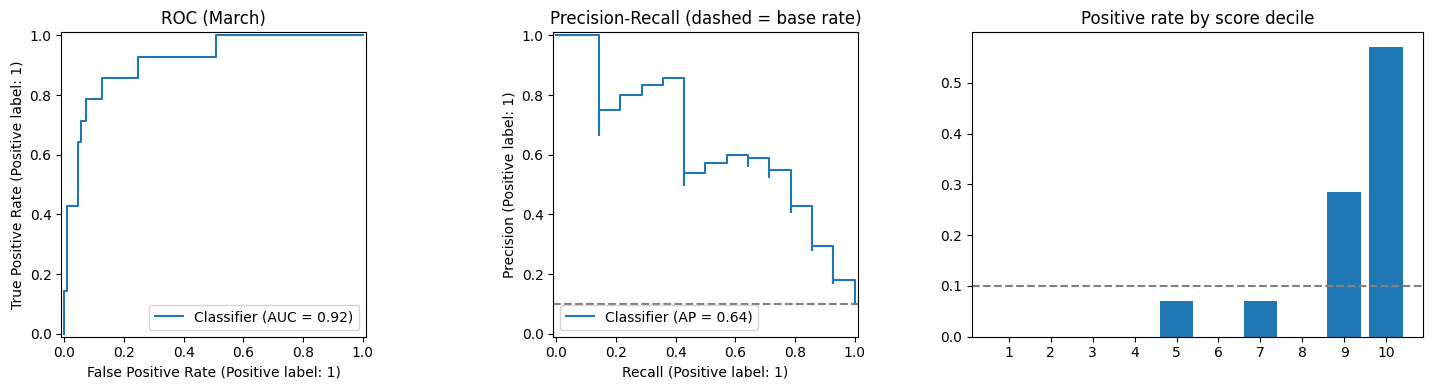

In [0]:
# The transaction data ends 2026-02-27, so the March hold-out from Cell 12 (>= 2026-03-01) is
# EMPTY and predict_proba fails on 0 rows. Recompute the temporal split here with the last
# full month (Feb 2026) as the untouched hold-out and refit on everything before it.
SPLIT = "2026-02-01"  # first day of the untouched hold-out month (data ends 2026-02-27)
dev  = data[data.Transaction_DateTime < SPLIT].reset_index(drop=True)
test = data[data.Transaction_DateTime >= SPLIT].reset_index(drop=True)
Xd, yd = make_features(dev), dev.y
Xt, yt = make_features(test), test.y
assert len(test) > 0 and len(dev) > 0, "Empty dev or test split"
print(f"hold-out split: development={len(dev)} (positive {yd.mean():.3f}) | test={len(test)} (positive {yt.mean():.3f})")

model = build_model(BEST).fit(Xd, yd)
p_test = model.predict_proba(Xt)[:, 1]
pred = (p_test >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()
metrics = {"roc_auc": roc_auc_score(yt, p_test), "pr_auc": average_precision_score(yt, p_test),
           "precision": precision_score(yt, pred), "recall": recall_score(yt, pred), "f1": f1_score(yt, pred),
           "flagged_share": pred.mean(), "prevalence": yt.mean()}
print(pd.Series({k: round(v, 4) for k, v in metrics.items()}).to_string()); print(f"confusion: TN={tn} FP={fp} FN={fn} TP={tp}")

# simple rule baseline for context
p90 = dev.Amount_NGN.quantile(0.9)
rule = ((test.International_Transaction == "Yes") | (test.Transaction_DateTime.dt.hour < 6) | (test.Amount_NGN >= p90)).astype(int)
print(f"\nRule baseline (international OR night OR top-10% amount): precision {precision_score(yt, rule):.3f} "
      f"recall {recall_score(yt, rule):.3f} F1 {f1_score(yt, rule):.3f} flagged {rule.mean():.1%}")

# bootstrap 95% confidence intervals (shows how much the numbers could move by chance)
rng = np.random.default_rng(SEED); n = len(yt); boots = []
for _ in range(300):
    i = rng.integers(0, n, n); yb, pb = yt.values[i], p_test[i]; pr = (pb >= THRESHOLD).astype(int)
    boots.append([roc_auc_score(yb, pb), average_precision_score(yb, pb), precision_score(yb, pr, zero_division=0), recall_score(yb, pr, zero_division=0)])
ci = pd.DataFrame(np.percentile(boots, [2.5, 50, 97.5], axis=0).T, index=["roc_auc", "pr_auc", "precision", "recall"], columns=["2.5%", "median", "97.5%"]).round(3)
print("\nBootstrap 95% CI (300 resamples of March):"); show(ci.reset_index())

# lift by score decile
t = pd.DataFrame({"score": p_test, "y": yt}); t["decile"] = pd.qcut(t.score.rank(method="first"), 10, labels=range(1, 11))
lift = t.groupby("decile", observed=True).agg(n=("y", "size"), positive_rate=("y", "mean"), avg_score=("score", "mean")).reset_index()
lift["lift_vs_base"] = (lift.positive_rate / yt.mean()).round(2); lift[["positive_rate", "avg_score"]] = lift[["positive_rate", "avg_score"]].round(3)
print("\nLift by score decile (10 = highest scores):"); show(lift)

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(yt, p_test, ax=ax[0]); ax[0].set_title("ROC (March)")
PrecisionRecallDisplay.from_predictions(yt, p_test, ax=ax[1]); ax[1].axhline(yt.mean(), ls="--", c="grey"); ax[1].set_title("Precision-Recall (dashed = base rate)")
ax[2].bar(lift.decile.astype(str), lift.positive_rate); ax[2].axhline(yt.mean(), ls="--", c="grey"); ax[2].set_title("Positive rate by score decile")
plt.tight_layout(); plt.show()

## 7. Finalise, save and reload the model
If `REFIT_ON_ALL_DATA=True` the model is refit on Jan-Mar (more data, but the March metrics above then no longer describe it).

In [0]:
import joblib
FINAL = build_model(BEST).fit(make_features(data), data.y) if REFIT_ON_ALL_DATA else model
META = {"algorithm": BEST, "threshold": THRESHOLD, "max_flag_rate": MAX_FLAG_RATE, "refit_on_all_data": REFIT_ON_ALL_DATA,
        "sklearn": sklearn.__version__, "test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
        "training_amount_max": float(dev.Amount_NGN.max()), "features": NUM + CAT}

MODEL_DIR = os.path.join(DATA_DIR, "model_artifacts")
try: os.makedirs(MODEL_DIR, exist_ok=True)
except Exception: MODEL_DIR = "/tmp/fintrust_model_artifacts"; os.makedirs(MODEL_DIR, exist_ok=True)
joblib.dump(FINAL, os.path.join(MODEL_DIR, "risk_model.joblib"))
json.dump(META, open(os.path.join(MODEL_DIR, "model_metadata.json"), "w"), indent=2)

# reload + verify the saved artifact reproduces the in-memory model
RELOADED = joblib.load(os.path.join(MODEL_DIR, "risk_model.joblib"))
assert np.allclose(RELOADED.predict_proba(Xt)[:, 1], FINAL.predict_proba(Xt)[:, 1]), "Reload mismatch"
print("saved + reloaded OK ->", MODEL_DIR)

saved + reloaded OK -> /tmp/fintrust_model_artifacts


## 8. LIVE scenario tester  (change the widgets, then re-run this section)
**Widgets** appear at the top of the notebook. Amount and date are free text so you can deliberately type bad values
(`abc`, `-50`, `not a date`) to test validation. Dropdowns include `<unseen>` (category the model never saw) and `<blank>` (missing).

In [0]:
WIDGET_DEFS = [
    ("txn_datetime", "text",     "2026-04-02 02:15:00", None, "Transaction_DateTime"),
    ("txn_amount",   "text",     "450000", None, "Amount_NGN"),
    ("txn_type",     "dropdown", "Transfer",   ALLOWED["Transaction_Type"] + ["<unseen>", "<blank>"], "Transaction_Type"),
    ("txn_channel",  "dropdown", "Mobile App", ALLOWED["Channel"] + ["<unseen>", "<blank>"], "Channel"),
    ("txn_device",   "dropdown", "Android",    ALLOWED["Device_Type"] + ["<unseen>", "<blank>"], "Device_Type"),
    ("txn_location", "dropdown", "Lagos",      ALLOWED["Location"] + ["<unseen>", "<blank>"], "Location"),
    ("txn_intl",     "dropdown", "Yes", ["Yes", "No", "Maybe (invalid)", "<blank>"], "International_Transaction"),
]
LOCAL_VALUES = {d[0]: d[2] for d in WIDGET_DEFS}      # used outside Databricks; edit to test locally

if IN_DATABRICKS:
    dbutils.widgets.removeAll()
    for name, kind, default, choices, label in WIDGET_DEFS:
        if kind == "text": dbutils.widgets.text(name, default, label)
        else: dbutils.widgets.dropdown(name, default, choices, label)

def read_widgets():
    v = {n: (dbutils.widgets.get(n) if IN_DATABRICKS else LOCAL_VALUES[n]) for n, *_ in WIDGET_DEFS}
    conv = lambda s: None if s == "<blank>" else ("UNSEEN_VALUE" if s == "<unseen>" else ("Maybe" if s.startswith("Maybe") else s))
    return {"Transaction_ID": "LIVE-001", "Transaction_DateTime": v["txn_datetime"], "Amount_NGN": v["txn_amount"],
            "Transaction_Type": conv(v["txn_type"]), "Channel": conv(v["txn_channel"]), "Device_Type": conv(v["txn_device"]),
            "Location": conv(v["txn_location"]), "International_Transaction": conv(v["txn_intl"])}

In [0]:
BANDS = {"high": THRESHOLD, "medium": THRESHOLD * 0.8}      # band heuristic (not independently validated)
OUT_COLS = ["row", "Transaction_ID", "status", "risk_score", "risk_review_flag_pred", "risk_band", "reject_reasons", "warnings"]

def score(data, model=FINAL):
    """Full workflow. Returns one output row per input row, order preserved."""
    clean, rej, warn, n = validate(data)
    for i, a in clean.Amount_NGN.items():
        if a > META["training_amount_max"]:
            warn.setdefault(i, []).append(f"Amount above largest training amount ({META['training_amount_max']:,.0f}); score is an extrapolation")
    sc = pd.Series(np.nan, index=range(n))
    if len(clean): sc.loc[clean.index] = model.predict_proba(make_features(clean))[:, 1]
    raw = pd.DataFrame([data] if isinstance(data, dict) else data).reset_index(drop=True)
    out = pd.DataFrame({"row": range(n)})
    out["Transaction_ID"] = raw["Transaction_ID"].values if "Transaction_ID" in raw else None
    out["status"] = ["rejected" if i in rej else "scored" for i in range(n)]
    out["risk_score"] = sc.round(4).values
    out["risk_review_flag_pred"] = [None if np.isnan(s) else ("Yes" if s >= THRESHOLD else "No") for s in sc]
    out["risk_band"] = [None if np.isnan(s) else ("High" if s >= BANDS["high"] else "Medium" if s >= BANDS["medium"] else "Low") for s in sc]
    out["reject_reasons"] = ["; ".join(rej.get(i, [])) for i in range(n)]
    out["warnings"] = ["; ".join(warn.get(i, [])) for i in range(n)]
    return out[OUT_COLS]

# reference values used to explain a score ("what if this field were ordinary?")
REF = {"Transaction_DateTime": pd.Timestamp("2026-04-02 12:00:00"), "Amount_NGN": float(dev.Amount_NGN.median()),
       "Transaction_Type": dev.Transaction_Type.mode()[0], "Channel": dev.Channel.mode()[0],
       "Device_Type": dev.Device_Type.mode()[0], "Location": dev.Location.mode()[0], "International_Transaction": "No"}

def explain(rec):
    """One-at-a-time occlusion: how much does the score change if each field is replaced by an ordinary value?
    Approximate (ignores interactions) - a guide, not a Shapley attribution."""
    base = score(rec).risk_score[0]; rows = []
    for k, ref in REF.items():
        alt = {**rec, k: ref}; s = score(alt).risk_score[0]
        rows.append({"field": k, "your_value": rec[k], "ordinary_value": ref, "score_if_ordinary": s, "contribution": round(base - s, 4)})
    return pd.DataFrame(rows).sort_values("contribution", key=abs, ascending=False)

live = read_widgets()
res = score(live)
print("INPUT :", {k: v for k, v in live.items() if k != "Transaction_ID"})
print()
show(res)
r = res.iloc[0]
if r.status == "rejected":
    print("\n>> REJECTED - not scored:", r.reject_reasons)
else:
    print(f"\n>> risk_score {r.risk_score:.3f} (threshold {THRESHOLD:.3f}) -> flag: {r.risk_review_flag_pred} | band: {r.risk_band}")
    if r.warnings: print(">> WARNING:", r.warnings)
    print("\nWhat is driving this score? (positive = pushes the score up vs an ordinary value)")
    show(explain(live).reset_index(drop=True))

INPUT : {'Transaction_DateTime': '2026-04-02 02:15:00', 'Amount_NGN': '450000', 'Transaction_Type': 'Transfer', 'Channel': 'Mobile App', 'Device_Type': 'POS Terminal', 'Location': 'Kano', 'International_Transaction': 'Yes'}



row,Transaction_ID,status,risk_score,risk_review_flag_pred,risk_band,reject_reasons,warnings
0,LIVE-001,scored,0.9812,Yes,High,,



>> risk_score 0.981 (threshold 0.773) -> flag: Yes | band: High

What is driving this score? (positive = pushes the score up vs an ordinary value)


field,your_value,ordinary_value,score_if_ordinary,contribution
Transaction_DateTime,2026-04-02 02:15:00,2026-04-02 12:00:00,0.6,0.3812
International_Transaction,Yes,No,0.7851,0.1961
Device_Type,POS Terminal,Android,0.9706,0.0106
Amount_NGN,450000,100492.595,0.9867,-0.0055
Location,Kano,Lagos,0.9825,-0.0013
Transaction_Type,Transfer,Transfer,0.9812,0.0
Channel,Mobile App,Mobile App,0.9812,0.0


## 9. Named scenario table (scores many cases at once, including deliberately bad inputs)

In [0]:
base = {"Transaction_ID": "", "Transaction_DateTime": "2026-04-02 14:30:00", "Amount_NGN": 12500, "Transaction_Type": "Card Purchase",
        "Channel": "POS", "Device_Type": "POS Terminal", "Location": "Lagos", "International_Transaction": "No"}
SCENARIOS = {
  "Everyday card purchase (day)":        {},
  "Small bill payment (day)":            {"Transaction_Type": "Bill Payment", "Amount_NGN": 4000, "Channel": "Web", "Device_Type": "Web Browser"},
  "Night-time transfer":                 {"Transaction_Type": "Transfer", "Transaction_DateTime": "2026-04-02 02:15:00", "Channel": "Mobile App", "Device_Type": "Android"},
  "Large international transfer, night": {"Transaction_Type": "Transfer", "Amount_NGN": 650000, "International_Transaction": "Yes", "Transaction_DateTime": "2026-04-02 02:15:00", "Channel": "Mobile App", "Device_Type": "Android"},
  "Large cash withdrawal at ATM":        {"Transaction_Type": "Cash Withdrawal", "Amount_NGN": 400000, "Channel": "ATM", "Device_Type": "ATM Terminal"},
  "Missing Device_Type + Location":      {"Device_Type": None, "Location": None},
  "Unseen Transaction_Type":             {"Transaction_Type": "Crypto Swap"},
  "Amount above training max (5m)":      {"Amount_NGN": 5_000_000},
  "BAD: amount = 'abc'":                 {"Amount_NGN": "abc"},
  "BAD: amount = -50":                   {"Amount_NGN": -50},
  "BAD: date = 'yesterday'":             {"Transaction_DateTime": "yesterday"},
  "BAD: international = 'Maybe'":        {"International_Transaction": "Maybe"},
}
recs = [{**base, **v, "Transaction_ID": k} for k, v in SCENARIOS.items()]
scen = score(recs); scen["Transaction_ID"] = list(SCENARIOS)
show(scen.drop(columns="row"))

Transaction_ID,status,risk_score,risk_review_flag_pred,risk_band,reject_reasons,warnings
Everyday card purchase (day),scored,0.0375,No,Low,,Unseen category in Transaction_Type: 'Card Purchase' (model has no information on it)
Small bill payment (day),scored,0.0224,No,Low,,Unseen category in Transaction_Type: 'Bill Payment' (model has no information on it)
Night-time transfer,scored,0.7321,No,Medium,,
"Large international transfer, night",scored,0.9928,Yes,High,,
Large cash withdrawal at ATM,scored,0.0224,No,Low,,Unseen category in Transaction_Type: 'Cash Withdrawal' (model has no information on it); Unseen category in Device_Type: 'ATM Terminal' (model has no information on it)
Missing Device_Type + Location,scored,0.0335,No,Low,,Unseen category in Transaction_Type: 'Card Purchase' (model has no information on it)
Unseen Transaction_Type,scored,0.0375,No,Low,,Unseen category in Transaction_Type: 'Crypto Swap' (model has no information on it)
Amount above training max (5m),scored,0.7072,No,Medium,,"Unseen category in Transaction_Type: 'Card Purchase' (model has no information on it); Amount above largest training amount (1,255,687); score is an extrapolation"
BAD: amount = 'abc',rejected,null,null,null,Amount_NGN is not numeric ('abc'),Unseen category in Transaction_Type: 'Card Purchase' (model has no information on it)
BAD: amount = -50,rejected,null,null,null,Amount_NGN must be > 0,Unseen category in Transaction_Type: 'Card Purchase' (model has no information on it)


## 10. What-if sweeps around your live inputs (amount and hour of day)

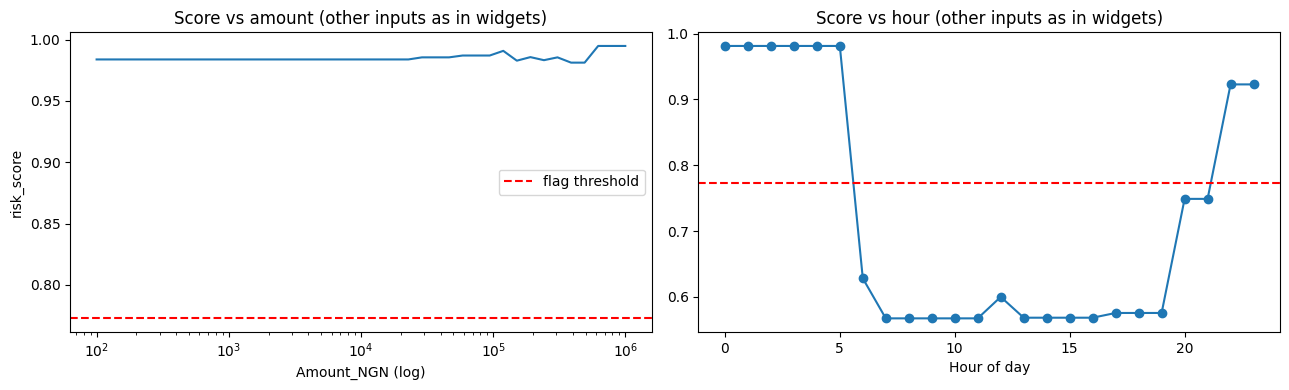

In [0]:
live = read_widgets()
if score(live).status[0] == "rejected":
    print("Fix the live input first:", score(live).reject_reasons[0])
else:
    amounts = np.unique(np.round(np.geomspace(100, 1_000_000, 40)))
    s_amt = score([{**live, "Amount_NGN": a} for a in amounts]).risk_score
    day = pd.to_datetime(live["Transaction_DateTime"]).normalize()
    hours = list(range(24))
    s_hr = score([{**live, "Transaction_DateTime": str(day + pd.Timedelta(hours=h))} for h in hours]).risk_score
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(amounts, s_amt); ax[0].set_xscale("log"); ax[0].axhline(THRESHOLD, ls="--", c="red", label="flag threshold"); ax[0].set_xlabel("Amount_NGN (log)"); ax[0].set_ylabel("risk_score"); ax[0].set_title("Score vs amount (other inputs as in widgets)"); ax[0].legend()
    ax[1].plot(hours, s_hr, marker="o"); ax[1].axhline(THRESHOLD, ls="--", c="red"); ax[1].set_xlabel("Hour of day"); ax[1].set_title("Score vs hour (other inputs as in widgets)")
    plt.tight_layout(); plt.show()

## 11. Batch scoring of a file (CSV or Excel with the required columns)

In [0]:
BATCH_FILE = None      # e.g. "/Volumes/main/default/fintrust/my_transactions.csv"
if BATCH_FILE:
    df_in = pd.read_csv(BATCH_FILE, dtype=object) if BATCH_FILE.endswith(".csv") else pd.read_excel(BATCH_FILE, dtype=object)
    out = score(df_in)
    show(out); print(out.status.value_counts().to_string())
    out.to_csv(os.path.join(MODEL_DIR, "batch_predictions.csv"), index=False); print("written to", MODEL_DIR)
else:
    print("Set BATCH_FILE to score a whole file. Required columns:", REQUIRED, "| optional:", OPTIONAL)

Set BATCH_FILE to score a whole file. Required columns: ['Transaction_DateTime', 'Transaction_Type', 'Amount_NGN', 'Channel', 'International_Transaction'] | optional: ['Transaction_ID', 'Device_Type', 'Location']


## Limitations (read before presenting)
* Synthetic data; `Risk_Review_Flag` is an educational label - results do **not** show real fraud detection ability.
* Predictive power is modest (see section 6 confidence intervals and lift table); the gain over the simple rule is small.
* `risk_score` is for ranking, not a calibrated probability; the Medium band is an unvalidated heuristic.
* Threshold depends on the assumed review capacity (`MAX_FLAG_RATE`).
* Only 3 months of data; no customer-history (velocity) features; fairness across city/segment not audited.
* Occlusion explanations are approximate and one-field-at-a-time.